# Task: Edge Detection Filters 

**Goal:** apply every filter we covered to **your own picture**, compare the results, and explain what you see.

**Rules**
- Use your own image (a photo with clear objects and some texture works best, not a blank wall).
- Write the code yourself where you see `# TODO`. Hints are given, not solutions.
- Every plot needs a title. Use `plt.figure(figsize=...)` so images are readable.

**Submit:** this notebook with outputs visible + your answers.

## Part 0: Setup & Load Your Image

(379, 445)


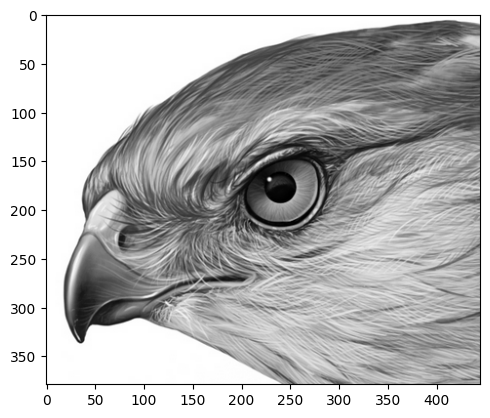

In [10]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

path = r"C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session2\images\hawk.png"

# TODO: load the image in grayscale and display it
img = cv.imread(path, 0)  #notice, it's loaded in grey, not displayed yet, this is just loading it into memory, u always forget that
# cv.imshow("Original Image", img)
# cv.waitKey(3000)
print(img.shape)
# cv.destroyAllWindows()
plt.imshow(img, cmap="gray")
plt.show()


**Question 0:** What is the size (height × width) of your image? Why do we convert to grayscale before edge detection?

it's (379x 445), 
an edge is the change in the brightness, and greyscale is the actual represtentation of brightness only, because grey-scaling is like flattening the image so we get the weights of each of the RGB's in it, this weight is the brightness of the color, we don't really care about it's channel, just the weight


## Part 1: Gradients (Sobel)

Compute the horizontal and vertical derivatives, then the magnitude and orientation.

Formulas: `mag = sqrt(gx² + gy²)` and `θ = arctan2(gy, gx)`

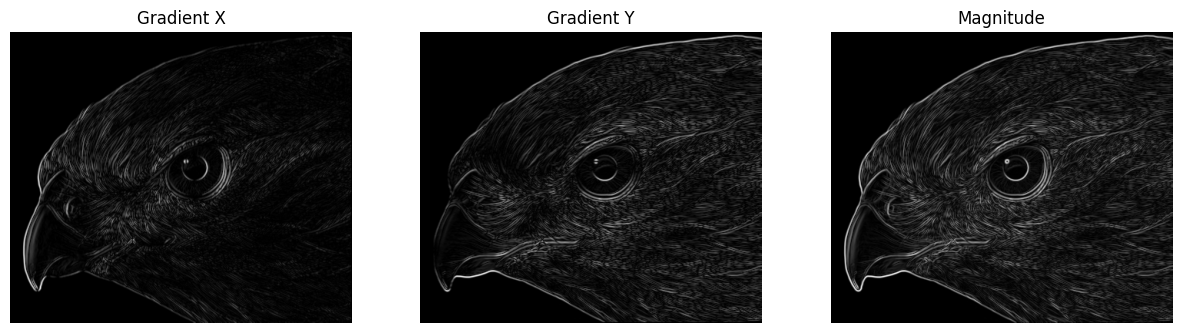

In [22]:
# TODO: compute grad_x and grad_y using cv2.Sobel with cv2.CV_64F and ksize=3
gradx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3) #dx=1 so the horizontal is changing and dy=0 
grady = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3) 

# TODO: compute magnitude and orientation (in degrees)
magnitude = np.sqrt(gradx **2 + grady** 2)
orientation = np.degrees(np.arctan2(grady, gradx))

# TODO: show grad_x, grad_y and magnitude side by side (1 row, 3 columns)
titles = ['Gradient X', 'Gradient Y', 'Magnitude']
images = [np.abs(gradx), np.abs(grady), magnitude]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap='gray'); plt.title(titles[i]); plt.axis('off')
plt.show()

**Question 1a:** Which gradient (X or Y) highlights vertical lines in your image? Point out one object in your picture that proves it.
x moves horizontally so it detects the vertical lines, y moves vertically, so it detects the change in the horizontal lines

**Question 1b:** Why do we use `cv2.CV_64F` instead of the default `uint8` here? (Hint: what happens to negative values?)
it's more descriptive, going from -ve to +ve means positive gradient and vice versa, and zero means there's no change wich is gonna yield dark spots only becasue all the negative values will be zero so we will lose alot in the image


## Part 2: Laplacian

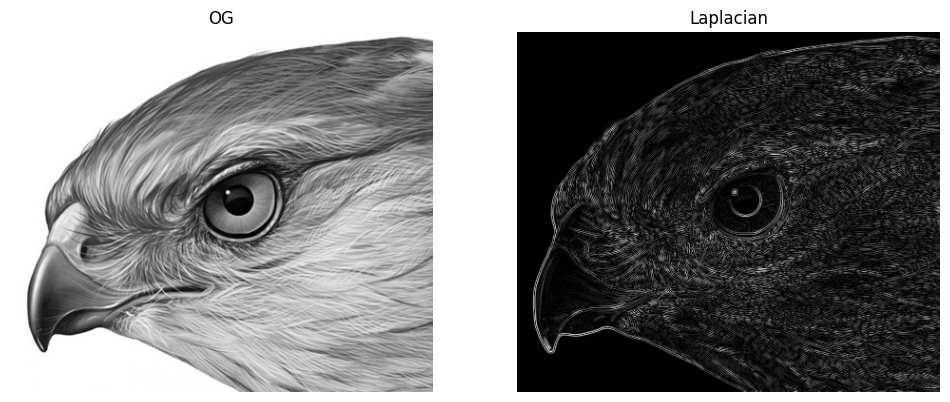

In [ ]:
# TODO: apply the Laplacian and show it next to the original
laplace = cv.Laplacian(img, cv.CV_64F, ksize=3)


# plt.imshow(laplace)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray'); plt.title('OG'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(np.abs(laplace), cmap='gray'); plt.title('Laplacian'); plt.axis('off')
plt.show()


**Question 2:** What is the difference between what the Laplacian gives you and what the Sobel gradients gave you? Does it tell you the edge direction?

sobel is the first derivative so it tells whether an edge exists or not, it's direction, and how storng it is laplace is the second derivative so it tells whether the change is  increasing or decreasing
*Your answer:* 

## Part 3: Canny

Try **three different threshold pairs** (low, high), for example a low pair, a medium pair, and a high pair.

In [ ]:
# TODO: run cv2.Canny with 3 different (low, high) threshold pairs
# TODO: show the original + the 3 results in one figure (1 row, 4 columns)
# Put the thresholds in each subplot title

**Question 3a:** What happens to the edges as you increase the thresholds?

**Question 3b:** List the 5 steps of the Canny pipeline in order.

*Your answers:* 

## Part 4: Roberts & Prewitt (Your Own Kernels)

Define the kernels yourself as NumPy arrays and apply them with `cv2.filter2D`.

- Roberts: 2×2 kernels
- Prewitt: 3×3 kernels (X and Y)

In [ ]:
# TODO: define roberts_x, roberts_y, prewitt_x, prewitt_y

# TODO: apply each with cv2.filter2D(img, -1, kernel)

# TODO: show the 4 results in a 2x2 grid

**Question 4:** Which one (Roberts or Prewitt) looks noisier on your image? Why do you think that is (think about kernel size)?

*Your answer:* 

## Part 5: Sobel 3×3 vs 5×5

In [ ]:
# TODO: apply Sobel in the X direction with ksize=3 and ksize=5, show side by side

**Question 5:** Describe the visible difference between the two. When would you choose 5×5 over 3×3?

*Your answer:* 

## Part 6: Gaussian, LoG & DoG

1. Blur the image with a Gaussian.
2. Apply the Laplacian on the blurred image (**LoG**).
3. Subtract two Gaussian blurs with different sigmas (**DoG**).

Then repeat the DoG with a **second pair of sigmas** (for example `(1, 2)` and `(2, 4)`) and compare.

In [ ]:
# TODO: blur, LoG, and DoG for the first sigma pair

# TODO: DoG for a second sigma pair

# TODO: show everything in one figure

**Question 6a:** Why do we blur before applying the Laplacian?

**Question 6b:** What changes in the DoG result when you increase the sigmas?

**Question 6c:** Which algorithm uses DoG for blob detection?

*Your answers:* 

## Part 7: Noise Experiment

Add noise to your image and see which filters survive.

In [ ]:
# TODO: create a noisy copy of your image
# Hint: noise = np.random.normal(0, 25, img.shape)
#       noisy = np.clip(img + noise, 0, 255).astype(np.uint8)

# TODO: apply Sobel (3x3), Laplacian and Canny on the NOISY image
# TODO: show the 3 results next to the same 3 results from the clean image (2 rows x 3 columns)

**Question 7:** Which filter was hurt the most by noise, and which handled it best? Explain why, using what you know about derivatives and smoothing.

*Your answer:* 

## Part 8: Final Comparison & Conclusion

Make one summary figure showing: Original, Sobel magnitude, Laplacian, Canny, LoG, DoG.

In [ ]:
# TODO: 2x3 grid with all six results and titles

**Final Question:** If you had to pick one method to detect the edges of objects in **your** image, which would you choose and why? Mention at least two trade-offs (noise, detail, thickness of edges, speed...).

*Your answer:* 

---

### Bonus (optional)
- Try your code on a second image with very different content (a face, text, a landscape) and describe what changed.
- Combine Sobel X and Y into the magnitude **without** using `np.sqrt` (hint: `cv2.magnitude`) and check that you get the same result.